In [1]:
# Импорты, версии и общие настройки — всё в одном месте, в начале блокнота
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:                       # sklearn нужен только проектам с моделями (с главы 6)
    import sklearn
    from sklearn.dummy import DummyRegressor
    from sklearn.linear_model import LinearRegression
    from sklearn.metrics import mean_absolute_error
    from sklearn.model_selection import train_test_split
except ImportError:
    sklearn = None

RANDOM_STATE = 42          # одно число для всей случайности: разбиения, модели, выборки
# папка с данными: data/ рядом с блокнотом (свой проект) или ../data (блокнот в папке курса)
DATA = next((p for p in (Path('data'), Path('../data')) if p.exists()), Path('data'))

pd.set_option('display.max_columns', 30)
print('Python', sys.version.split()[0], '| данные:', DATA.resolve())
for lib in (pd, np, matplotlib, sklearn):
    if lib is None:
        continue
    print(f'{lib.__name__:<11}{lib.__version__}')
import math
from IPython.display import display, Markdown

Python 3.12.14 | данные: /private/tmp/course-learner-2026/data
pandas     3.0.6
numpy      2.4.6
matplotlib 3.10.9
sklearn    1.8.0


# Почему доставка опаздывает

## 1. Цель и главное
Найти масштаб и связанные с опозданиями группы для руководителя. Среди пригодных времён опоздали 441/1841 (24%); для всей выгрузки крайние границы 23.5–25.4%. Пешим нужно пересмотреть обещание, а не называть их причиной всех задержек.

**Вывод:** дальше проверяем состав групп, потерянные времена и знаменатель оценок.

## 2. Данные и очистка

In [2]:
raw=pd.read_csv(DATA/"deliveries.csv",parse_dates=["created"])
valid=raw.actual_min.between(1,299)
ok=raw.loc[valid].copy()
ok["late"]=ok.actual_min>ok.promised_min
ok["delay"]=ok.actual_min-ok.promised_min
ok["hour"]=ok.created.dt.hour
log={"всего":len(raw),"без времени":int(raw.actual_min.isna().sum()),"невозможное время":int((raw.actual_min.notna()&~valid).sum()),"осталось":len(ok)}
print(log)
print(raw.assign(excluded=~valid).groupby("courier").excluded.agg(["sum","size"]))

{'всего': 1877, 'без времени': 25, 'невозможное время': 11, 'осталось': 1841}
         sum  size
courier           
авто      15   581
вело      16   888
пеший      5   408


**Вывод:** отсутствующее время не равняется вовремя. Проверена концентрация исключений по курьеру; общая доля потерь сама по себе не гарантирует точность подгрупп.

## 3. Масштаб и группы

23.954372623574145 7.0 20.0
courier    68.645056
items      22.301217
hour       20.904281
weather    14.992576
shop_id    13.096405
dtype: float64


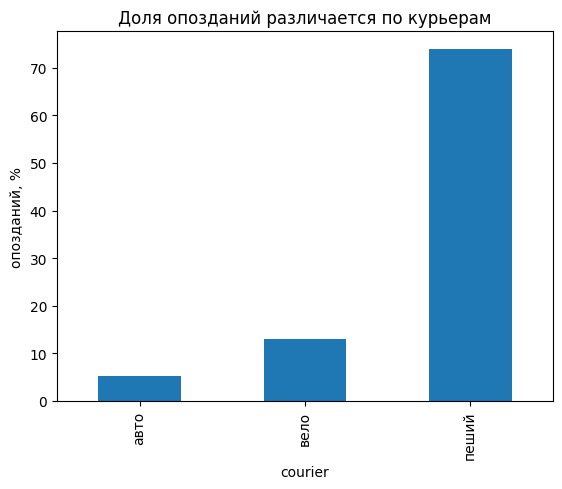

In [3]:
print(ok.late.mean()*100,ok.loc[ok.late,"delay"].median(),ok.loc[ok.late,"delay"].quantile(.9))
ranking={}
for col in ["courier","weather","shop_id","items","hour"]:
 t=ok.groupby(col).late.agg(["size","mean"])
 t=t.loc[t["size"]>=50,"mean"]
 ranking[col]=100*(t.max()-t.min())
print(pd.Series(ranking).sort_values(ascending=False))
ax=ok.groupby("courier").late.mean().mul(100).plot.bar()
ax.set_title("Доля опозданий различается по курьерам")
ax.set_ylabel("опозданий, %")
plt.show()

**Вывод:** размер группы рядом с долей обязателен; связь признака с опозданиями ещё не измеряет его причинное влияние.

## 4. Обещание и кофейня

In [4]:
print(ok.pivot_table(index="promised_min",columns="courier",values="late").mul(100))
walk=ok[(ok.courier=="пеший")&(ok.promised_min==30)]
print("Обещание",math.ceil(walk.actual_min.quantile(.8)/5)*5)
print(ok.groupby(["courier",ok.shop_id.eq("KZN-2")]).agg(n=("late","size"),median_min=("actual_min","median"),km=("distance_km","median")))

courier            авто       вело      пеший
promised_min                                 
30            17.647059  24.369748  69.716088
45             1.438849   7.770270  89.534884
60             4.301075  21.428571        NaN
Обещание 40
                   n  median_min   km
courier shop_id                      
авто    False    483        30.0  3.4
        True      83        36.0  3.5
вело    False    743        31.0  2.6
        True     129        35.0  2.5
пеший   False    343        36.0  1.3
        True      60        40.5  1.3


**Вывод:** квантиль 80% даёт 40 минут для исторической подгруппы. Это кандидат обещания для проверки, не гарантия на будущей нагрузке.

## 5. Календарь и оценки

                 late       snow
created                         
2026-09-13  22.556391   0.000000
2026-09-20  25.000000   0.000000
2026-09-27  29.870130   0.000000
2026-10-04  29.710145   0.000000
2026-10-11  18.367347   0.000000
2026-10-18  18.571429   0.000000
2026-10-25  20.437956   0.000000
2026-11-01  25.490196   1.307190
2026-11-08  24.031008  17.829457
2026-11-15  22.916667  28.472222
2026-11-22  29.411765  69.117647
2026-11-29  25.694444   3.472222


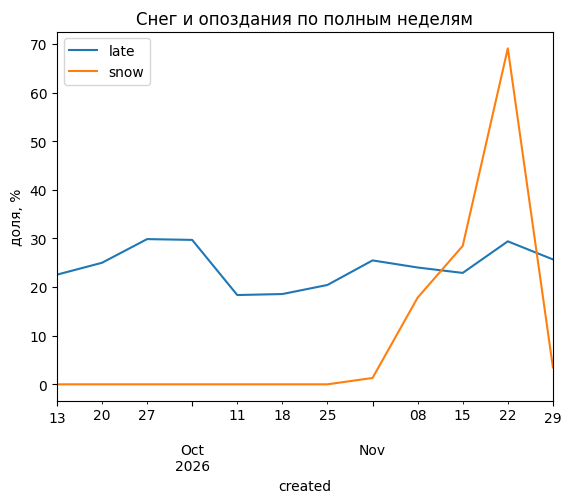

Низкие среди ответивших 53 75 70.7


In [5]:
daily=ok.set_index("created").resample("D").late.agg(["size","mean"])
weekly=ok.assign(snow=ok.weather.eq("снег")).set_index("created").resample("W")[["late","snow"]].mean().iloc[1:-1]*100
print(weekly)
ax=weekly.plot()
ax.set_title("Снег и опоздания по полным неделям")
ax.set_ylabel("доля, %")
plt.show()
r=ok.loc[ok.delay>10,"rating"].dropna()
print("Низкие среди ответивших",int(r.le(3).sum()),len(r),round(r.le(3).mean()*100,1))

**Вывод:** неполные недели исключены как календарный артефакт. Низких оценок 53 из 75 ответивших (70.7%); всего задержанных больше 10 минут 130, молчание 55 не означает удовлетворённость.

## 6. Две новые группы

In [6]:
for query in ["distance_km <= 1.5","items >= 5"]:
 mask=ok.eval(query)
 print(query,int(mask.sum()),100*ok.loc[mask,"late"].mean(),100*ok.loc[~mask,"late"].mean())
 print(ok.assign(group=mask).groupby(["courier","group"]).late.agg(["size","mean"]))

distance_km <= 1.5 409 52.81173594132029 15.712290502793296
               size      mean
courier group                
авто    False   528  0.049242
        True     38  0.105263
вело    False   798  0.127820
        True     74  0.148649
пеший   False   106  0.915094
        True    297  0.676768
items >= 5 225 38.22222222222222 21.967821782178216
               size      mean
courier group                
авто    False   492  0.042683
        True     74  0.121622
вело    False   777  0.113256
        True     95  0.263158
пеший   False   347  0.708934
        True     56  0.928571


**Вывод:** проверены короткое расстояние и большой заказ, размеры групп и перепад долей показаны выше. Сравнение внутри курьера помогает заметить смешение; эти наблюдения не превращаем в доказанный эффект.

## 7. Повторяемый отчёт

In [7]:
def delivery_report(raw):
    ok=raw.loc[raw.actual_min.between(1,299)].copy()
    if len(ok)==0:
        return {"late_pct":None,"worst_courier":None,"worst_shop":None,"peak_hours":[],"fair_promise":None}
    ok["late"]=ok.actual_min>ok.promised_min
    ok["hour"]=ok.created.dt.hour
    h=ok.groupby("hour").late.agg(["size","mean"])
    walk=ok.loc[(ok.courier=="пеший") & (ok.promised_min==30),"actual_min"]
    return {"late_pct":round(100*ok.late.mean(),1),"worst_courier":ok.groupby("courier").late.mean().idxmax(),"worst_shop":ok.groupby("shop_id").late.mean().idxmax(),"peak_hours":sorted(h.index[(h["size"]>=50)&(h["mean"]>0.25)].tolist()),"fair_promise":None if walk.empty else math.ceil(walk.quantile(.8)/5)*5}
raw=pd.read_csv(DATA/"deliveries.csv",parse_dates=["created"])
print(delivery_report(raw))
print("Без пеших",delivery_report(raw.loc[raw.courier!="пеший"]))
print("Пусто",delivery_report(raw.iloc[:0]))

{'late_pct': np.float64(24.0), 'worst_courier': 'пеший', 'worst_shop': 'KZN-2', 'peak_hours': [12, 13, 18, 19], 'fair_promise': 40}
Без пеших {'late_pct': np.float64(9.9), 'worst_courier': 'вело', 'worst_shop': 'KZN-2', 'peak_hours': [], 'fair_promise': None}
Пусто {'late_pct': None, 'worst_courier': None, 'worst_shop': None, 'peak_hours': [], 'fair_promise': None}


**Вывод:** период без пеших возвращает fair_promise=None, полностью пустой период — None для метрик и [] для часов. Отсутствующая подгруппа не имеет нулевого времени.

## 8. Рекомендации

**Вывод:** предложить пилот обещания 40 минут для пеших, изучить расстояния и сборку KZN-2; в рейтингах явно подписывать ответивших. Чистый отчёт пересчитывается на другом периоде, а причинность требует отдельной проверки.